# Treino — SpacialCNN — CV global misturado

Pipeline atualizado para 5-fold cross-validation estratificada.

Inclui:
- classes de altura por quantis;
- normalização calculada apenas no treino de cada fold;
- treino, validação, métricas e gráficos por fold.


In [1]:
# ============================================================
# 1. IMPORTS E CONFIGURAÇÃO GLOBAL
# ============================================================

import os
import time
import json
import re
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import rasterio
import geopandas as gpd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# -----------------------------
# Caminhos
# -----------------------------
RAW_BASE_DIR  = Path(r"D:\Tese_data_refinada\_example_patches")
VALIDATION_DIR = Path(r"D:\Tese_data_refinada\Areas_gpkg")
OUTPUT_DIR    = Path("outputs_fch/spacial_cnn")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# -----------------------------
# Experiência
# -----------------------------
SEED           = 42
TARGET_COLUMN  = "rh_opt_098"
TARGET_SCALE   = 100.0   # cm → metros
VAL_SIZE       = 0.20

# -----------------------------
# Hiperparâmetros 
# -----------------------------
BATCH_SIZE     = 64
LR             = 3e-4
WEIGHT_DECAY   = 0.0
EPOCHS         = 40
PATIENCE       = 15
LOG_EVERY      = 5      # imprime métricas completas a cada N épocas

# -----------------------------
# Hardware
# -----------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM disponível: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False

set_seed(SEED)

Dispositivo: cuda
GPU: NVIDIA GeForce RTX 3060
VRAM disponível: 12.9 GB


In [2]:
# ============================================================
# 2. DATASET E AUGMENTATION
# ============================================================

class FCHDataset(Dataset):
    def __init__(self, X, y, transform=None):
        self.X = X.astype(np.float32)
        self.y = y.astype(np.float32)
        self.transform = transform

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        x = self.X[idx].copy()
        if self.transform is not None:
            x = self.transform(x)
        return (torch.tensor(x, dtype=torch.float32),
                torch.tensor(self.y[idx], dtype=torch.float32))


def base_augmentation(x):
    """Rotações e flips aleatórios (apenas treino)."""
    k = np.random.randint(0, 4)
    if k > 0:
        x = np.rot90(x, k, axes=(1, 2)).copy()
    if np.random.rand() > 0.5:
        x = np.flip(x, axis=2).copy()
    if np.random.rand() > 0.5:
        x = np.flip(x, axis=1).copy()
    return x

In [3]:
# ============================================================
# 3. CARREGAMENTO DOS TIFs
# ============================================================
import re
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from pathlib import Path

def extract_point_id(filename):
    m = re.search(r"point_(\d+)_", filename)
    if m is None:
        raise ValueError(f"Não consegui extrair point_id de: {filename}")
    return int(m.group(1))

def build_target_dict(gdf, target_column):
    possible_id_cols = ["point_id", "POINT_ID", "id", "ID", "fid", "FID"]
    id_col = next((c for c in possible_id_cols if c in gdf.columns), None)
    ids     = gdf[id_col].astype(int).values if id_col else gdf.index.astype(int).values
    targets = gdf[target_column].values
    return {int(pid): float(t) for pid, t in zip(ids, targets) if not pd.isna(t)}

def get_valid_band_indices(metadata_path):
    with open(metadata_path, "r", encoding="utf-8") as f:
        meta = json.load(f)
    raster_names = meta.get("raster_names", [])
    valid_indices = [
        i for i, name in enumerate(raster_names)
        if "CHM" not in name.upper() and "LIDAR" not in name.upper() and "OTHER" not in name.upper()
    ]
    removed = [n for n in raster_names if "CHM" in n.upper() or "LIDAR" in n.upper() or "OTHER" in n.upper()]
    if removed:
        print(f"   Bandas removidas (leakage): {removed}")
    return valid_indices, raster_names

def load_all_regions_tifs(raw_base_dir, validation_dir, target_column="rh_opt_098"):
    raw_base_dir   = Path(raw_base_dir)
    validation_dir = Path(validation_dir)
    X_list, y_list, region_list, pid_list = [], [], [], []
    channels_ref = None

    print("-> A ler TIFs e cruzar com GeoPackages...")
    for area_dir in sorted(raw_base_dir.iterdir()):
        if not area_dir.is_dir(): continue
        area_name = area_dir.name
        gpkg_path = validation_dir / f"{area_name}_HEIGHT_Dataset.gpkg"
        if not gpkg_path.exists():
            print(f"   [{area_name}] GeoPackage não encontrado — ignorado.")
            continue
        metas = list(area_dir.glob("*.json"))
        if not metas:
            print(f"   [{area_name}] metadata JSON não encontrado — ignorado.")
            continue

        print(f"\nÁrea: {area_name}")
        gdf = gpd.read_file(gpkg_path)
        target_dict  = build_target_dict(gdf, target_column)
        valid_idx, _ = get_valid_band_indices(metas[0])

        if channels_ref is None:
            channels_ref = len(valid_idx)
        elif len(valid_idx) != channels_ref:
            raise ValueError(f"Canais incompatíveis em {area_name}: esperado {channels_ref}, obtido {len(valid_idx)}")

        n_loaded = n_no_target = 0
        for tif in sorted(area_dir.rglob("*.tif")):
            pid = extract_point_id(tif.name)
            if pid not in target_dict: n_no_target += 1; continue
            with rasterio.open(tif) as src:
                patch = src.read().astype(np.float32)[valid_idx]
            X_list.append(patch); y_list.append(target_dict[pid])
            region_list.append(area_name); pid_list.append(pid)
            n_loaded += 1
        print(f"   Carregados: {n_loaded} | Sem target: {n_no_target}")

    if not X_list: raise RuntimeError("Nenhum patch carregado.")
    X = np.stack(X_list).astype(np.float32)
    y = np.array(y_list, dtype=np.float32)
    regions  = np.array(region_list)
    point_ids = np.array(pid_list)
    print(f"\nResumo: X={X.shape} | y={y.shape} | regiões={sorted(set(regions))}")
    print(f"NaNs em X: {np.isnan(X).mean()*100:.3f}%")
    return X, y, regions, point_ids

def make_loro_split(X, y, regions, point_ids, val_region):
    """
    Nova versão: Divide apenas em Treino e Validação.
    A região escolhida fica para validação, o resto vai TUDO para treino.
    """
    val_mask   = regions == val_region
    train_mask = ~val_mask
    
    if val_mask.sum() == 0:
        raise ValueError(f"Região de validação '{val_region}' não encontrada.")

    split = dict(
        X_train_raw=X[train_mask], y_train_raw=y[train_mask],
        regions_train=regions[train_mask], point_ids_train=point_ids[train_mask],
        X_val_raw=X[val_mask],   y_val_raw=y[val_mask],
        regions_val=regions[val_mask], point_ids_val=point_ids[val_mask]
    )
    
    print(f"\nSplit LORO | Validação: {val_region}")
    print(f"  Treino:    {split['X_train_raw'].shape[0]} amostras | regiões={sorted(set(split['regions_train']))}")
    print(f"  Validação: {split['X_val_raw'].shape[0]} amostras | regiões={sorted(set(split['regions_val']))}")
    return split

In [4]:
# ============================================================
# 4. NORMALIZAÇÃO SEM LEAKAGE
# ============================================================

def normalize_from_train(X_train_raw, X_val_raw):
    mean = np.nanmean(X_train_raw, axis=(0, 2, 3), keepdims=True)
    std  = np.nanstd(X_train_raw,  axis=(0, 2, 3), keepdims=True)
    std  = np.where(std == 0, 1e-6, std)

    X_train = np.nan_to_num((X_train_raw - mean) / std, nan=0., posinf=0., neginf=0.).astype(np.float32)
    X_val   = np.nan_to_num((X_val_raw   - mean) / std, nan=0., posinf=0., neginf=0.).astype(np.float32)

    print(f"Normalização concluída | média_treino≈{np.mean(X_train):.5f} | std_treino≈{np.std(X_train):.5f}")
    return X_train, X_val, mean, std

In [5]:
# ============================================================
# 5. ARQUITETURA 
# ============================================================

class SpacialCNN(nn.Module):
    """
    CNN leve com dilated convolution para patches 15×15 multi-sensor.
    in_channels = n_bandas + n_sensores (máscaras de disponibilidade)
    """
    def __init__(self, in_channels: int):
        super().__init__()

        self.encoder = nn.Sequential(
            # Bloco 1 — extracção local, 15×15 → 15×15
            nn.Conv2d(in_channels, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.GELU(),

            # Bloco 2 — 15×15 → 15×15
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.GELU(),

            # Bloco 3 dilated — campo recetor 9×9 sem reduzir resolução
            nn.Conv2d(128, 128, kernel_size=3, padding=2, dilation=2, bias=False),
            nn.BatchNorm2d(128),
            nn.GELU(),

            # Bloco 4 — 15×15 → 15×15
            nn.Conv2d(128, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.GELU(),
        )

        # Reduz para 3×3 antes do MLP (evita flatten de 15×15×256 = 57 600 neurónios)
        self.pool = nn.AdaptiveAvgPool2d((3, 3))

        self.regressor = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 3 * 3, 256, bias=False),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Dropout(0.3),

            nn.Linear(256, 64),
            nn.GELU(),
            nn.Dropout(0.2),

            nn.Linear(64, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.encoder(x)
        x = self.pool(x)
        return self.regressor(x).squeeze(1)


def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Parâmetros totais: {total:,} | treináveis: {trainable:,}")
    return total, trainable

In [6]:
# ============================================================
# 6. FUNÇÕES DE MÉTRICAS E TREINO
# ============================================================

def regression_metrics(y_true, y_pred):
    y_true_np = np.array(y_true).flatten()
    y_pred_np = np.array(y_pred).flatten()

    rmse = np.sqrt(mean_squared_error(y_true_np, y_pred_np))
    mae = mean_absolute_error(y_true_np, y_pred_np)
    r2 = r2_score(y_true_np, y_pred_np)
    bias = np.mean(y_pred_np - y_true_np)
    covariancia = np.cov(y_true_np, y_pred_np)[0, 1]
    
    # Cálculo do %RMSE (RMSE / média real * 100)
    y_true_mean = np.mean(y_true_np)
    pct_rmse = (rmse / y_true_mean) * 100 if y_true_mean > 0 else float("nan")
    
    return {
        "RMSE": rmse,
        "%RMSE": pct_rmse, 
        "MAE": mae,
        "R2": r2,
        "Bias": bias,
        "Covariancia": covariancia 
    }


def _eval_loader(model, loader):
    """Devolve (y_true, y_pred) em numpy para um loader completo."""
    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for bX, by in loader:
            all_preds.append(model(bX.to(device)).cpu().numpy())
            all_targets.append(by.numpy())
    return np.concatenate(all_targets), np.concatenate(all_preds)


def train_spacialcnn_cnn(
    model, train_loader, val_loader, model_name,
    epochs=40, patience=15, lr=3e-4, weight_decay=0.0, log_every=5,
):
    """
    Treina a SpacialCNN com early stopping.

    Imprime a cada época (ou quando há melhoria):
      - MSE treino/val
      - RMSE val (metros)
      - %RMSE val  ← RMSE relativo à média de y_true na validação
      - MAE val
      - R² val
      - learning rate atual
      - tempo da época
      - ETA estimado
    """
    model = model.to(device)
    criterion  = nn.MSELoss()
    optimizer  = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler  = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)
    ckpt_path  = OUTPUT_DIR / f"ckpt_{model_name}.pth"

    best_val_loss   = np.inf
    best_epoch      = 0
    epochs_no_impr  = 0
    history = {"epoch": [], "train_mse": [], "val_mse": [],
               "val_rmse": [], "val_pct_rmse": [], "val_mae": [], "val_r2": [], "lr": []}

    # Pré-calcular média de y_val para o %RMSE
    y_val_all = np.concatenate([by.numpy() for _, by in val_loader])
    y_val_mean = float(np.mean(y_val_all))

    header = (f"{'Época':>6}  {'MSE_tr':>8}  {'MSE_val':>8}  "
              f"{'RMSE_val':>9}  {'%RMSE':>6}  {'MAE':>7}  {'R²':>6}  "
              f"{'LR':>9}  {'s/ep':>5}  {'ETA':>6}")
    print(f"\n{'─'*len(header)}")
    print(header)
    print(f"{'─'*len(header)}")

    epoch_times = []

    for epoch in range(1, epochs + 1):
        t0 = time.time()

        # --- Treino ---
        model.train()
        train_loss_sum = 0.0
        for bX, by in train_loader:
            bX, by = bX.to(device), by.to(device)
            optimizer.zero_grad()
            loss = criterion(model(bX), by)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * bX.size(0)
        train_mse = train_loss_sum / len(train_loader.dataset)

        # --- Validação (com métricas completas) ---
        y_true_v, y_pred_v = _eval_loader(model, val_loader)
        val_mse     = float(mean_squared_error(y_true_v, y_pred_v))
        val_rmse    = float(np.sqrt(val_mse))
        val_pct_rmse = (val_rmse / y_val_mean) * 100 if y_val_mean > 0 else float("nan")
        val_mae     = float(mean_absolute_error(y_true_v, y_pred_v))
        val_r2      = float(r2_score(y_true_v, y_pred_v))

        scheduler.step(val_mse)
        current_lr = optimizer.param_groups[0]["lr"]

        elapsed = time.time() - t0
        epoch_times.append(elapsed)
        remaining_epochs = epochs - epoch
        avg_ep_time = np.mean(epoch_times[-10:])   # média das últimas 10 épocas
        eta_s = remaining_epochs * avg_ep_time
        eta_str = f"{int(eta_s//60)}m{int(eta_s%60):02d}s" if eta_s >= 60 else f"{eta_s:.0f}s"

        improved = val_mse < best_val_loss
        if improved:
            best_val_loss  = val_mse
            best_epoch     = epoch
            epochs_no_impr = 0
            torch.save(model.state_dict(), ckpt_path)
            flag = " ⭐"
        else:
            epochs_no_impr += 1
            flag = ""

        history["epoch"].append(epoch)
        history["train_mse"].append(train_mse)
        history["val_mse"].append(val_mse)
        history["val_rmse"].append(val_rmse)
        history["val_pct_rmse"].append(val_pct_rmse)
        history["val_mae"].append(val_mae)
        history["val_r2"].append(val_r2)
        history["lr"].append(current_lr)

        if epoch == 1 or epoch % log_every == 0 or improved:
            print(
                f"{epoch:>6}  {train_mse:>8.4f}  {val_mse:>8.4f}  "
                f"{val_rmse:>8.3f}m  {val_pct_rmse:>5.1f}%  {val_mae:>6.3f}m  {val_r2:>6.3f}  "
                f"{current_lr:>9.2e}  {elapsed:>4.1f}s  {eta_str:>6}{flag}"
            )

        if epochs_no_impr >= patience:
            print(f"\nEarly stopping na época {epoch} (sem melhoria há {patience} épocas).")
            break

    print(f"{'─'*len(header)}")
    print(f"Melhor época: {best_epoch} | Melhor val MSE: {best_val_loss:.4f} | RMSE: {np.sqrt(best_val_loss):.3f}m")
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    return model, pd.DataFrame(history)


def evaluate_model(model, val_loader, model_name):
    rows, preds_dict = [], {}
    # Avaliar apenas a validação
    for split_name, loader in [("val", val_loader)]:
        y_true, y_pred = _eval_loader(model, loader)
        m = regression_metrics(y_true, y_pred)
        rows.append({"model": model_name, "split": split_name, **m})
        preds_dict[split_name] = {"y_true": y_true, "y_pred": y_pred}
    return pd.DataFrame(rows), preds_dict

In [7]:
# ============================================================
# 7. GRÁFICOS
# ============================================================

def save_fig(path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Figura: {path}")


def plot_learning_curves(hist, model_name, region):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].plot(hist["epoch"], hist["train_mse"], label="treino")
    axes[0].plot(hist["epoch"], hist["val_mse"],   label="validação", linestyle="--")
    axes[0].set(title="MSE", xlabel="Época", ylabel="MSE")
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(hist["epoch"], hist["val_rmse"],     label="RMSE (m)")
    axes[1].plot(hist["epoch"], hist["val_mae"],      label="MAE (m)", linestyle="--")
    axes[1].set(title="RMSE & MAE (validação)", xlabel="Época", ylabel="m")
    axes[1].legend(); axes[1].grid(alpha=0.3)

    axes[2].plot(hist["epoch"], hist["val_pct_rmse"], color="darkorange", label="%RMSE")
    ax2r = axes[2].twinx()
    ax2r.plot(hist["epoch"], hist["val_r2"], color="steelblue", linestyle=":", label="R²")
    axes[2].set(title="%RMSE & R² (validação)", xlabel="Época", ylabel="%RMSE")
    ax2r.set_ylabel("R²")
    axes[2].legend(loc="upper right"); ax2r.legend(loc="upper center")
    axes[2].grid(alpha=0.3)

    plt.suptitle(f"spacialCNN — {region}", fontsize=12, fontweight="bold")
    #save_fig(OUTPUT_DIR / f"curvas_{model_name}_{region}.png")


def plot_true_vs_pred(y_true, y_pred, model_name, split_name, region):
    mn, mx = min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    plt.figure(figsize=(5, 5))
    plt.scatter(y_true, y_pred, alpha=0.6, s=12)
    plt.plot([mn, mx], [mn, mx], "--k")
    plt.xlabel("Real (m)"); plt.ylabel("Previsto (m)")
    plt.title(f"{model_name} | {split_name} | {region}\nRMSE={rmse:.3f}m  R²={r2:.3f}")
    plt.grid(alpha=0.3)
    #save_fig(OUTPUT_DIR / f"{model_name}_{split_name}_{region}_ytrue_ypred.png")


def plot_residuals(y_true, y_pred, model_name, split_name, region):
    residuals = y_pred - y_true
    plt.figure(figsize=(5, 4))
    plt.scatter(y_pred, residuals, alpha=0.6, s=12)
    plt.axhline(0, linestyle="--", color="k")
    plt.xlabel("Previsto (m)"); plt.ylabel("Resíduo (m)")
    plt.title(f"Resíduos | {model_name} | {split_name} | {region}")
    plt.grid(alpha=0.3)
    #save_fig(OUTPUT_DIR / f"{model_name}_{split_name}_{region}_residuos.png")

 PIPELINE FCH — SpacialCNN — CV global misturado
-> A ler TIFs e cruzar com GeoPackages...

Área: Mafra
   Bandas removidas (leakage): ['Mafra_20200000_CHM_AGBD_ALL', 'Mafra_20200000_CHM_BGBD_ALL', 'Mafra_20200000_CHM_LBD_ALL', 'Mafra_20200000_CHM_SBD_ALL']
   Carregados: 463 | Sem target: 0

Área: Monsanto
   Bandas removidas (leakage): ['Monsanto_20200000_CHM_AGBD_ALL', 'Monsanto_20200000_CHM_BGBD_ALL', 'Monsanto_20200000_CHM_LBD_ALL', 'Monsanto_20200000_CHM_SBD_ALL']
   Carregados: 455 | Sem target: 0

Área: Pombal
   Bandas removidas (leakage): ['Pombal_20200000_CHM_AGBD_ALL', 'Pombal_20200000_CHM_BGBD_ALL', 'Pombal_20200000_CHM_LBD_ALL', 'Pombal_20200000_CHM_SBD_ALL']
   Carregados: 850 | Sem target: 0

Área: SerraLousa
   Bandas removidas (leakage): ['SerraLousa_20200000_CHM_AGBD_ALL', 'SerraLousa_20200000_CHM_BGBD_ALL', 'SerraLousa_20200000_CHM_LBD_ALL', 'SerraLousa_20200000_CHM_SBD_ALL']
   Carregados: 5825 | Sem target: 0

Área: SintraCascais
   Bandas removidas (leakage): ['S

region,Mafra,Monsanto,Pombal,SerraLousa,SintraCascais,VPA
fold,,,,,,
1,93,91,170,1165,147,107
2,93,91,170,1165,147,107
3,93,91,170,1165,147,107
4,92,91,170,1165,148,107
5,92,91,170,1165,147,107



=== Distribuição de classes de altura por fold ===


height_class,0,1,2,3,4
fold,,,,,
1,355,354,355,355,354
2,356,355,354,354,354
3,357,353,353,356,354
4,356,354,354,357,352
5,355,354,354,355,354



=== Distribuição região × classe de altura por fold ===


region       Mafra                Monsanto                  ... SintraCascais  \
height_class     0   1   2   3  4        0   1   2   3   4  ...             0   
fold                                                        ...                 
1               30  25  17  16  5       13  20  25  19  14  ...            31   
2               30  26  17  15  5       13  20  25  19  14  ...            32   
3               30  26  17  15  5       14  19  25  19  14  ...            32   
4               30  26  16  16  4       13  20  26  19  13  ...            32   
5               30  26  16  16  4       13  20  25  19  14  ...            32   

region                       VPA                 
height_class   1   2   3   4   0   1   2   3  4  
fold                                             
1             23  33  34  26  41  28  19  13  6  
2             22  32  34  27  41  28  19  13  6  
3             22  32  35  26  41  28  18  13  7  
4             22  33  35  26  41  28  18  13  7  
5             22  33  34  26  41  28  19  12  7  

[5 rows x 30 columns]


=== Resultados por fold ===


,model,split,RMSE,%RMSE,MAE,R2,Bias,Covariancia,cv_type,fold,n_train,n_val
0,SpacialCNN,val,5.461375,35.672219,4.166826,0.480733,-0.304071,31.657290,global_region_height_stratified,1,7091,1773
1,SpacialCNN,val,5.597206,36.496724,4.335433,0.470084,-0.153753,28.654983,global_region_height_stratified,2,7091,1773
2,SpacialCNN,val,5.629185,36.759443,4.392909,0.475352,0.022496,31.106534,global_region_height_stratified,3,7091,1773
3,SpacialCNN,val,5.624865,36.524256,4.218188,0.499166,-0.317516,35.554106,global_region_height_stratified,4,7091,1773
4,SpacialCNN,val,5.576181,36.503449,4.351703,0.466132,-0.580493,26.573223,global_region_height_stratified,5,7092,1772



=== Resumo global — média ± desvio padrão das 5 folds ===


RMSE                %RMSE                 MAE            \
                mean       std       mean       std      mean       std   
model                                                                     
SpacialCNN  5.577762  0.068538  36.391218  0.416526  4.293012  0.095845   

                  R2                Bias           Covariancia            
                mean       std      mean       std        mean       std  
model                                                                     
SpacialCNN  0.478293  0.012899 -0.266667  0.222955   30.709227  3.385852


Resultados guardados em: outputs_fch\spacial_cnn\cv_global_misturado_estratificado


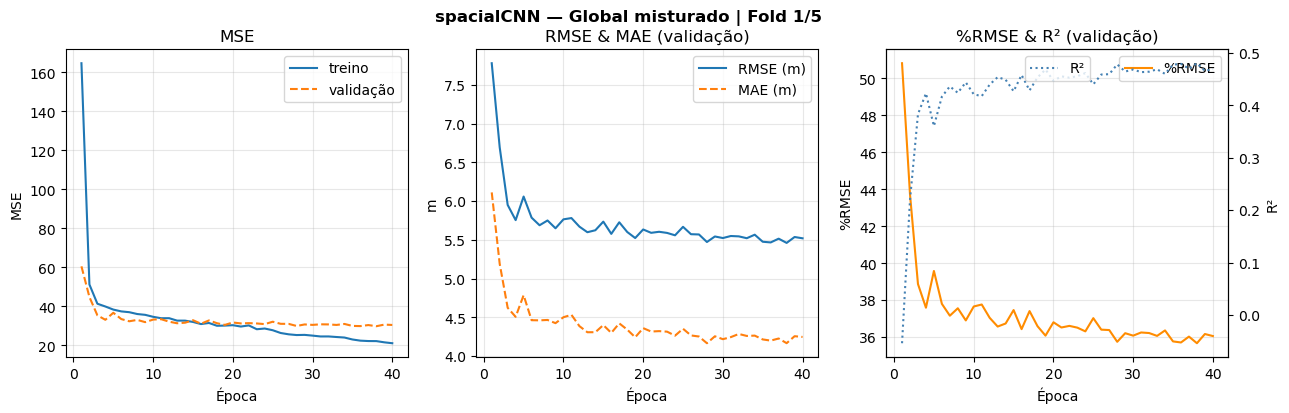

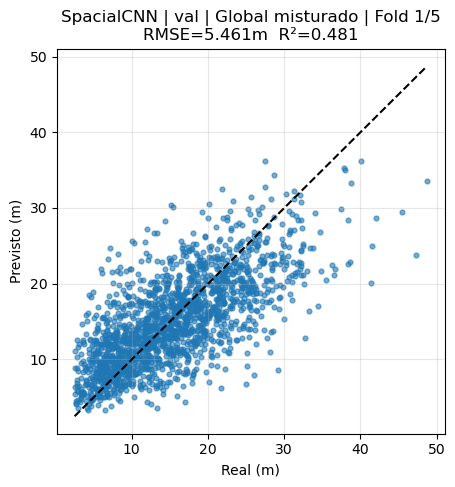

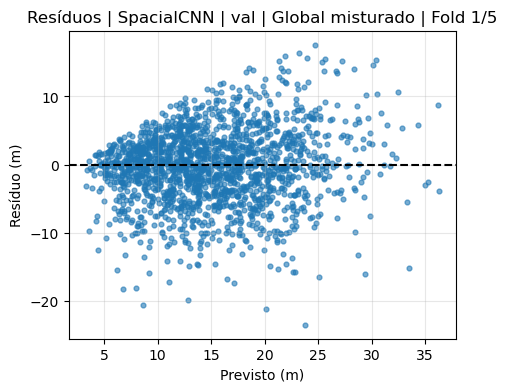

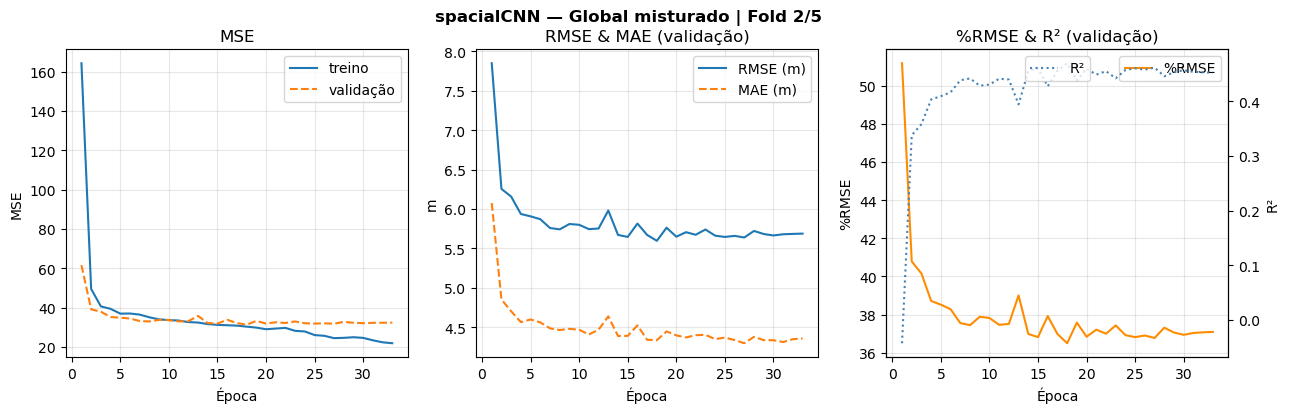

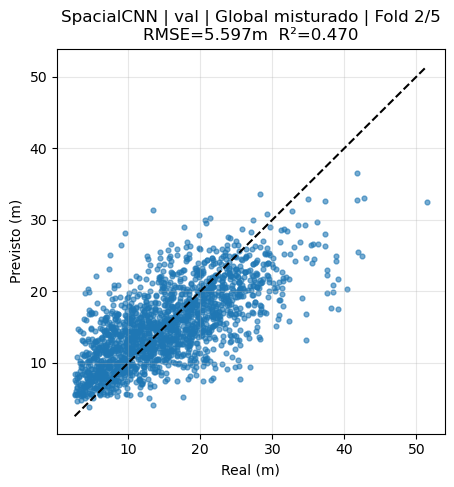

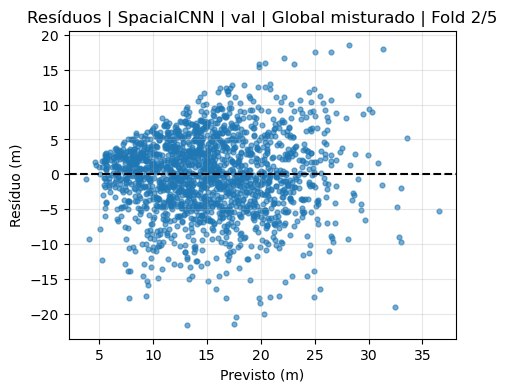

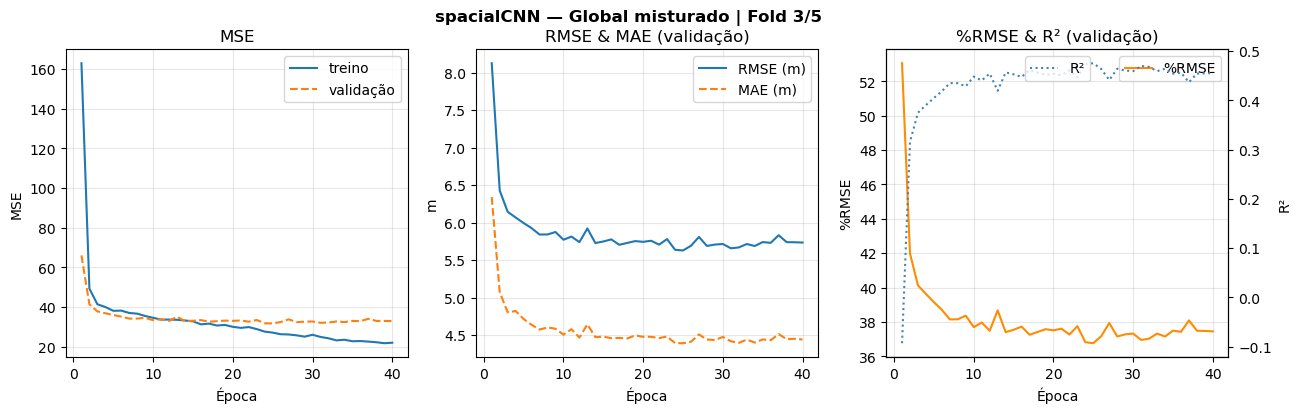

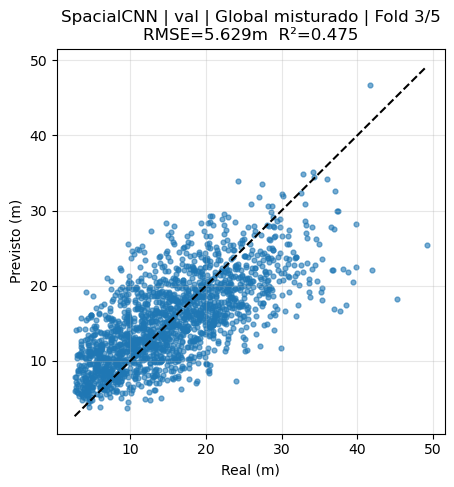

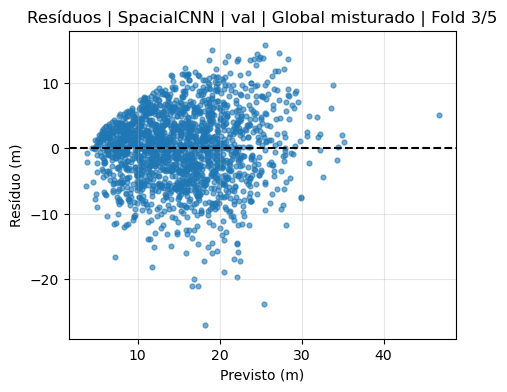

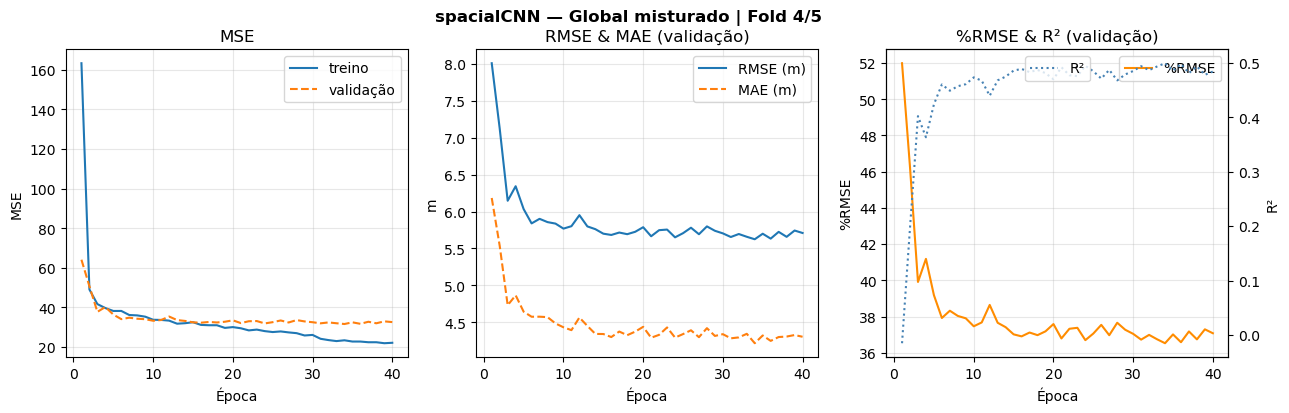

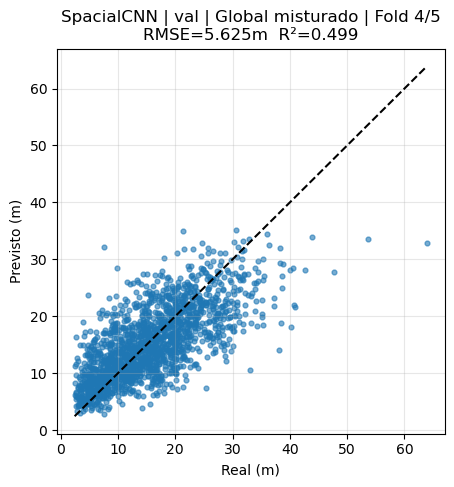

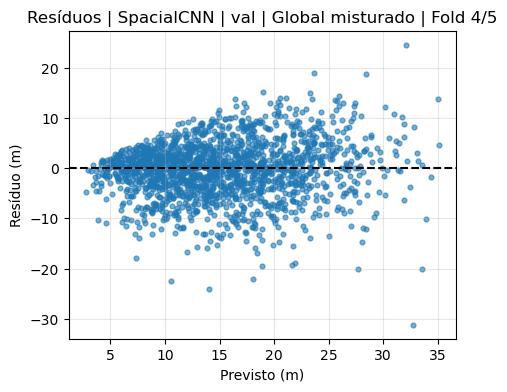

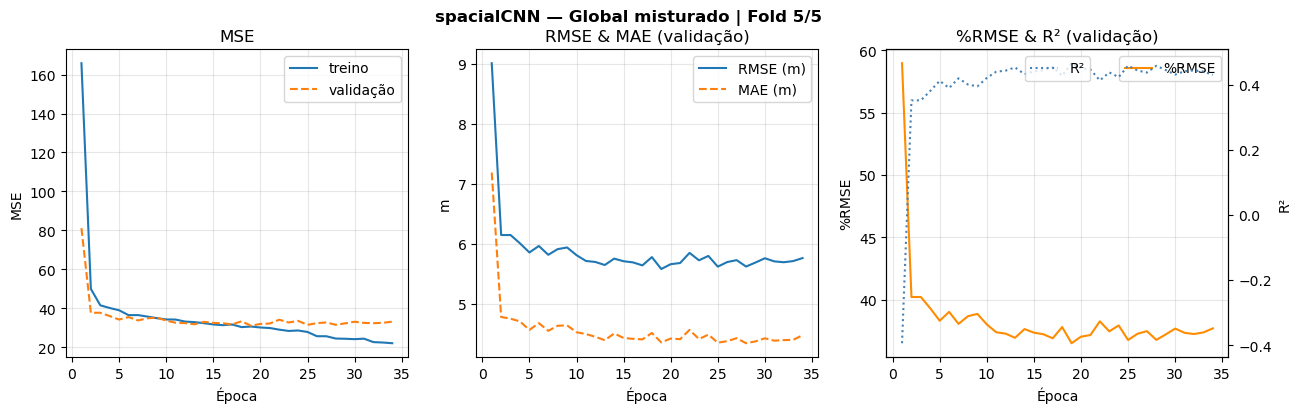

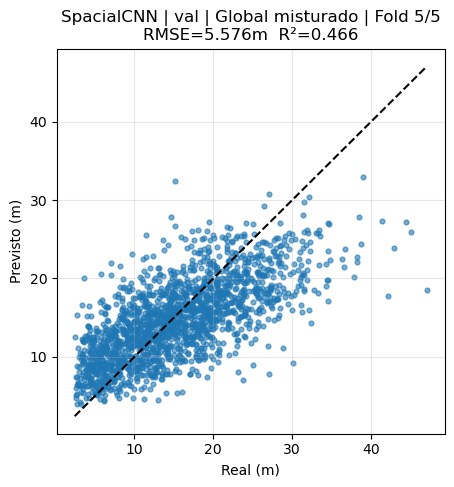

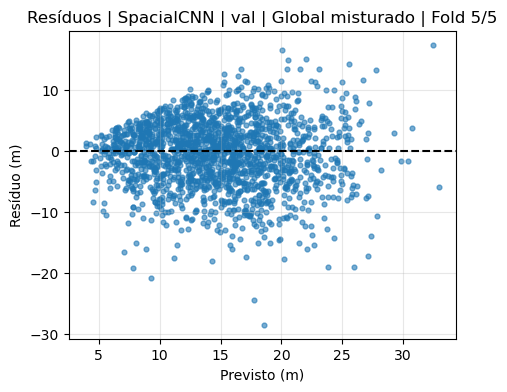

In [8]:

# ============================================================
# FUNÇÕES AUXILIARES PARA CROSS-VALIDATION ESTRATIFICADA
# ============================================================

from sklearn.model_selection import StratifiedKFold

N_SPLITS = 5
N_HEIGHT_BINS = 5


def safe_name(text):
    """Nome seguro para ficheiros/checkpoints."""
    return re.sub(r"[^A-Za-z0-9_-]+", "_", str(text))


def make_height_classes(y, n_bins=5):
    """
    Cria classes de altura por quantis.

    Exemplo com n_bins=5:
      classe 0 = alturas mais baixas
      classe 4 = alturas mais altas

    Usar quantis é melhor do que intervalos fixos quando a distribuição
    de alturas é desequilibrada, porque tenta deixar as classes com
    número semelhante de amostras.
    """
    y = np.asarray(y, dtype=float)

    if len(y) == 0:
        raise ValueError("y está vazio.")

    if len(np.unique(y)) < 2 or n_bins <= 1:
        classes = np.zeros(len(y), dtype=int)
        bins = np.array([np.min(y), np.max(y)])
        return classes, bins

    classes, bins = pd.qcut(
        pd.Series(y),
        q=n_bins,
        labels=False,
        duplicates="drop",
        retbins=True,
    )

    classes = classes.astype(int).to_numpy()
    return classes, bins


def choose_height_classes_for_cv(y, n_splits=5, max_bins=5, label=""):
    """
    Escolhe classes de altura válidas para StratifiedKFold.

    Se alguma classe tiver menos amostras do que n_splits, reduz o número
    de classes até a estratificação ser possível.
    """
    y = np.asarray(y, dtype=float)

    if len(y) < n_splits:
        raise ValueError(
            f"{label} tem apenas {len(y)} amostras. "
            f"Não dá para fazer {n_splits} folds."
        )

    max_bins_possible = min(max_bins, len(np.unique(y)), len(y))

    for n_bins in range(max_bins_possible, 0, -1):
        height_classes, bin_edges = make_height_classes(y, n_bins=n_bins)
        counts = pd.Series(height_classes).value_counts()

        if counts.min() >= n_splits:
            if n_bins < max_bins:
                print(
                    f"AVISO {label}: reduzi as classes de altura de "
                    f"{max_bins} para {n_bins}, porque havia classes "
                    f"com menos de {n_splits} amostras."
                )
            return height_classes, bin_edges

    raise ValueError(
        f"{label}: não foi possível criar classes de altura válidas "
        f"para {n_splits} folds."
    )


def choose_region_height_strata_for_cv(y, regions, n_splits=5, max_bins=5):
    """
    Cria estratos combinados região + classe_altura.

    Isto força cada fold a ter, tanto quanto possível:
      - proporção semelhante de classes de altura
      - proporção semelhante de pontos de cada região
      - proporção semelhante de cada combinação região/classe_altura
    """
    y = np.asarray(y, dtype=float)
    regions = np.asarray(regions)

    if len(y) < n_splits:
        raise ValueError(
            f"Dataset tem apenas {len(y)} amostras. "
            f"Não dá para fazer {n_splits} folds."
        )

    max_bins_possible = min(max_bins, len(np.unique(y)), len(y))

    for n_bins in range(max_bins_possible, 0, -1):
        height_classes, bin_edges = make_height_classes(y, n_bins=n_bins)
        strata = np.array([
            f"{region}__h{height_class}"
            for region, height_class in zip(regions, height_classes)
        ])

        counts = pd.Series(strata).value_counts()

        if counts.min() >= n_splits:
            if n_bins < max_bins:
                print(
                    f"AVISO global: reduzi as classes de altura de "
                    f"{max_bins} para {n_bins}, porque havia combinações "
                    f"região/classe_altura com menos de {n_splits} amostras."
                )
            return height_classes, strata, bin_edges

    min_region_count = pd.Series(regions).value_counts().min()
    raise ValueError(
        "Não foi possível criar estratos região + altura para "
        f"{n_splits} folds. A região mais pequena tem {min_region_count} amostras. "
        "Confirma se todas as regiões têm pelo menos 5 pontos e se não há "
        "combinações região/classe_altura demasiado raras."
    )


def print_height_bins(bin_edges, target_scale=100.0):
    """Mostra os limites das classes de altura em metros."""
    print("\nLimites das classes de altura:")
    for i in range(len(bin_edges) - 1):
        lo = bin_edges[i] / target_scale
        hi = bin_edges[i + 1] / target_scale
        print(f"  Classe {i}: {lo:.2f} m até {hi:.2f} m")


def build_loaders_from_indices(X_all, y_all, train_idx, val_idx):
    """
    Normaliza sem leakage e cria DataLoaders.
    A média e o desvio padrão são calculados só no treino do fold.
    """
    X_train, X_val, _, _ = normalize_from_train(
        X_all[train_idx],
        X_all[val_idx],
    )

    y_train = y_all[train_idx] / TARGET_SCALE
    y_val = y_all[val_idx] / TARGET_SCALE

    print(
        f"\ny_train: média={y_train.mean():.3f}m | std={y_train.std():.3f}m | "
        f"min={y_train.min():.2f}m | max={y_train.max():.2f}m"
    )
    print(
        f"y_val:   média={y_val.mean():.3f}m | std={y_val.std():.3f}m | "
        f"min={y_val.min():.2f}m | max={y_val.max():.2f}m"
    )

    train_ds = FCHDataset(X_train, y_train, transform=base_augmentation)
    val_ds = FCHDataset(X_val, y_val)

    train_loader = DataLoader(
        train_ds,
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=(len(train_ds) % BATCH_SIZE == 1),
    )

    val_loader = DataLoader(
        val_ds,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )

    return train_loader, val_loader


def run_fold(
    X_all,
    y_all,
    regions_all,
    pids_all,
    train_idx,
    val_idx,
    model_name,
    fold_label,
    result_extra=None,
):
    """Treina e avalia uma fold."""
    result_extra = result_extra or {}

    print("\n" + "=" * 65)
    print(f" {fold_label}")
    print("=" * 65)
    print(f"Treino: {len(train_idx)} amostras")
    print(f"Validação: {len(val_idx)} amostras")
    print(f"Regiões treino: {sorted(set(regions_all[train_idx]))}")
    print(f"Regiões validação: {sorted(set(regions_all[val_idx]))}")

    set_seed(SEED)

    train_loader, val_loader = build_loaders_from_indices(
        X_all,
        y_all,
        train_idx,
        val_idx,
    )

    num_channels = X_all.shape[1]
    model = SpacialCNN(in_channels=num_channels)

    print("\nArquitetura: SpacialCNN")
    count_parameters(model)

    model, history = train_spacialcnn_cnn(
        model,
        train_loader,
        val_loader,
        model_name=model_name,
        epochs=EPOCHS,
        patience=PATIENCE,
        lr=LR,
        weight_decay=WEIGHT_DECAY,
        log_every=LOG_EVERY,
    )

    results_df, preds = evaluate_model(
        model,
        val_loader,
        model_name="SpacialCNN",
    )

    for key, value in result_extra.items():
        results_df[key] = value

    results_df["n_train"] = len(train_idx)
    results_df["n_val"] = len(val_idx)

    val_row = results_df[results_df["split"] == "val"].iloc[0]
    print(
        f"\n>>> Validação Final | RMSE={val_row['RMSE']:.3f}m | "
        f"%RMSE={val_row['%RMSE']:.1f}% | MAE={val_row['MAE']:.3f}m | "
        f"R²={val_row['R2']:.3f}"
    )

    plot_learning_curves(
        history,
        model_name=model_name,
        region=fold_label,
    )

    plot_true_vs_pred(
        preds["val"]["y_true"],
        preds["val"]["y_pred"],
        model_name="SpacialCNN",
        split_name="val",
        region=fold_label,
    )

    plot_residuals(
        preds["val"]["y_true"],
        preds["val"]["y_pred"],
        model_name="SpacialCNN",
        split_name="val",
        region=fold_label,
    )

    return results_df, history


def summarize_final_results(final_df, group_cols):
    """Resumo final com média e desvio padrão."""
    metric_cols = ["RMSE", "%RMSE", "MAE", "R2", "Bias", "Covariancia"]

    summary = (
        final_df[final_df["split"] == "val"]
        .groupby(group_cols)[metric_cols]
        .agg(["mean", "std"])
    )

    display(summary)
    return summary


# ============================================================
# 8. PIPELINE 2 — CROSS-VALIDATION GLOBAL COM REGIÕES MISTURADAS
# ============================================================

OUTPUT_DIR = Path("outputs_fch/spacial_cnn/cv_global_misturado_estratificado")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 65)
print(" PIPELINE FCH — SpacialCNN — CV global misturado")
print("=" * 65)

X_all, y_all, regions_all, pids_all = load_all_regions_tifs(
    RAW_BASE_DIR,
    VALIDATION_DIR,
    target_column=TARGET_COLUMN,
)

available_regions = sorted(np.unique(regions_all))
print(f"\nRegiões disponíveis: {available_regions}")

height_classes, strata, bin_edges = choose_region_height_strata_for_cv(
    y_all,
    regions_all,
    n_splits=N_SPLITS,
    max_bins=N_HEIGHT_BINS,
)

print_height_bins(bin_edges, target_scale=TARGET_SCALE)

skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED,
)

all_results = []
all_histories = {}
fold_ids = np.full(len(y_all), fill_value=-1, dtype=int)

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X_all, strata),
    start=1,
):
    fold_ids[val_idx] = fold

    model_name = f"SpacialCNN_global_mixed_fold{fold}"
    fold_label = f"Global misturado | Fold {fold}/{N_SPLITS}"

    results_df, history = run_fold(
        X_all=X_all,
        y_all=y_all,
        regions_all=regions_all,
        pids_all=pids_all,
        train_idx=train_idx,
        val_idx=val_idx,
        model_name=model_name,
        fold_label=fold_label,
        result_extra={
            "cv_type": "global_region_height_stratified",
            "fold": fold,
        },
    )

    all_results.append(results_df)
    all_histories[fold] = history

# ============================================================
# VERIFICAÇÃO DA ESTRATIFICAÇÃO
# ============================================================

fold_assignments_df = pd.DataFrame({
    "region": regions_all,
    "point_id": pids_all,
    "y_cm": y_all,
    "y_m": y_all / TARGET_SCALE,
    "height_class": height_classes,
    "stratum": strata,
    "fold": fold_ids,
})

print("\n=== Distribuição de regiões por fold ===")
display(pd.crosstab(fold_assignments_df["fold"], fold_assignments_df["region"]))

print("\n=== Distribuição de classes de altura por fold ===")
display(pd.crosstab(fold_assignments_df["fold"], fold_assignments_df["height_class"]))

print("\n=== Distribuição região × classe de altura por fold ===")
display(
    pd.crosstab(
        fold_assignments_df["fold"],
        [fold_assignments_df["region"], fold_assignments_df["height_class"]],
    )
)

# ============================================================
# RESUMO FINAL
# ============================================================

final_df = pd.concat(all_results, ignore_index=True)

print("\n=== Resultados por fold ===")
display(final_df)

print("\n=== Resumo global — média ± desvio padrão das 5 folds ===")
summary_global = summarize_final_results(final_df, group_cols=["model"])

final_df.to_csv(OUTPUT_DIR / "resultados_cv_global_misturado.csv", index=False)
fold_assignments_df.to_csv(OUTPUT_DIR / "fold_assignments_cv_global_misturado.csv", index=False)
summary_global.to_csv(OUTPUT_DIR / "resumo_cv_global_misturado.csv")

print(f"\nResultados guardados em: {OUTPUT_DIR}")
